In [1]:
# Celda 1: Importacion de librerias esenciales
import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

print("Librerias importadas correctamente.")

Librerias importadas correctamente.


In [2]:
# Celda 2: Carga y estructuracion del Dataset
np.random.seed(42)
n = 200

datos = {
    'ID_Registro': [f'REG-{i:03d}' for i in range(1, n + 1)],
    'Horas_Dedicacion': np.random.normal(loc=16, scale=4, size=n).clip(6, 32),
    'Calificacion_Final': np.random.normal(loc=78, scale=9, size=n).clip(45, 100),
    'Modalidad': np.random.choice(['Virtual', 'Presencial'], size=n, p=[0.6, 0.4])
}

df = pd.DataFrame(datos)
print("Primeras 5 filas del Dataset:")
display(df.head())

Primeras 5 filas del Dataset:


,ID_Registro,Horas_Dedicacion,Calificacion_Final,Modalidad
0,REG-001,17.986857,81.220086,Virtual
1,REG-002,15.446943,83.047061,Virtual
2,REG-003,18.590754,87.747461,Virtual
3,REG-004,22.092119,87.484218,Presencial
4,REG-005,15.063387,65.600976,Presencial


In [3]:
# Celda 3: Perfilado de Datos y Limpieza
print("--- INFORMACION GENERAL DEL DATASET ---")
print(df.info())
print("\nCantidad de valores nulos por columna:")
print(df.isnull().sum())

df = df.drop_duplicates()

--- INFORMACION GENERAL DEL DATASET ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID_Registro         200 non-null    object 
 1   Horas_Dedicacion    200 non-null    float64
 2   Calificacion_Final  200 non-null    float64
 3   Modalidad           200 non-null    object 
dtypes: float64(2), object(2)
memory usage: 6.4+ KB
None

Cantidad de valores nulos por columna:
ID_Registro           0
Horas_Dedicacion      0
Calificacion_Final    0
Modalidad             0
dtype: int64


In [4]:
# Celda 4: Estadisticas Descriptivas Basicas
print("--- ESTADISTICAS DESCRIPTIVAS ---")
print(df[['Horas_Dedicacion', 'Calificacion_Final']].describe().T[['mean', 'std', 'min', 'max']])

--- ESTADISTICAS DESCRIPTIVAS ---
                         mean       std        min         max
Horas_Dedicacion    15.839311  3.717497   6.000000   26.880677
Calificacion_Final  78.709441  8.682916  48.828594  100.000000


In [5]:
# Celda 5: Calculo de Intervalo de Confianza (95%)
media = df['Calificacion_Final'].mean()
error_est = stats.sem(df['Calificacion_Final'])
ic = stats.t.interval(0.95, len(df['Calificacion_Final']) - 1, loc=media, scale=error_est)

print(f"Media Muestral de Calificaciones: {media:.2f}")
print(f"Intervalo de Confianza (95%): {ic}")

Media Muestral de Calificaciones: 78.71
Intervalo de Confianza (95%): (np.float64(77.49870904306795), np.float64(79.92017248695291))


In [6]:
# Celda 6: Prueba t de Student
grupo_virtual = df[df['Modalidad'] == 'Virtual']['Calificacion_Final']
grupo_presencial = df[df['Modalidad'] == 'Presencial']['Calificacion_Final']

t_stat, p_valor = stats.ttest_ind(grupo_virtual, grupo_presencial)

print(f"--- PRUEBA T DE STUDENT ---")
print(f"Estadistico t: {t_stat:.4f}")
print(f"P-valor: {p_valor:.4f}")

if p_valor > 0.05:
    print("Interpretacion: No hay diferencias significativas (p > 0.05). Rendimiento equivalente.")
else:
    print("Interpretacion: Si existen diferencias significativas.")

--- PRUEBA T DE STUDENT ---
Estadistico t: 0.5864
P-valor: 0.5583
Interpretacion: No hay diferencias significativas (p > 0.05). Rendimiento equivalente.


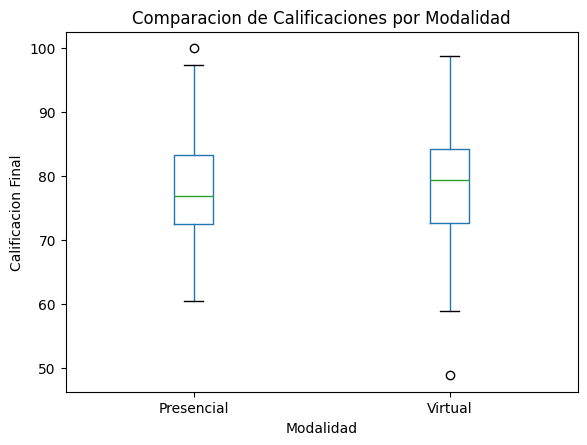

In [7]:
# Celda 7: Generacion de Grafico (Boxplot)
df.boxplot(column='Calificacion_Final', by='Modalidad', grid=False)
plt.title('Comparacion de Calificaciones por Modalidad')
plt.suptitle('') 
plt.xlabel('Modalidad')
plt.ylabel('Calificacion Final')
plt.show()